# 13 - Auto-encodeur convolutif : apprendre a reconstruire le normal

Un auto-encodeur compresse l'image dans un goulot etroit puis la reconstruit. Entraine sur des
pieces BONNES seulement, il apprend a reconstruire le normal ; la ou il reconstruit mal, l'image
s'ecarte du normal. La carte d'erreur de reconstruction est la carte d'anomalie.

Ce que tu vas voir, tout le code etant ecrit dans ce notebook :
1. le protocole des anomalies (que des normales en train et val) sur MVTec bottle ;
2. l'auto-encodeur, son goulot (LE reglage), l'entrainement avec courbe en direct ;
3. reconstruction, carte d'erreur, lissage, score, seuil = quantile 0,99 des normales de
   validation, AUROC image et pixel ;
4. pourquoi il echoue sur une TEXTURE (Magnetic Tile) : l'erreur du defaut se noie dans celle de la texture ;
5. l'export ONNX (image -> carte, score) et la carte du modele servie par la production.

Prerequis : le socle de la toolbox ; donnees `python tools/get_data/get_mvtec_bottle.py`
(CC BY-NC-SA 4.0, usage non commercial) et `python tools/get_data/get_magnetic_tile.py`.

Duree en mode QUICK sur un CPU 2 coeurs : environ 4 minutes (128 px).

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter -> 8 Modele
  -> 6 Augmenter, 7 Charger par lots, 9 Perte et optimiseur, 10 Entrainer (une seule fonction)
  -> 11 Evaluer (cartes, score, seuil sur les normales de validation, test)
  -> variante : le meme fil sur une texture -> 12 Sauvegarder et exporter
  -> 13 Predire (dans "Passer en production")
```

L'etape 2 (importer et explorer) n'est pas refaite ici : notebooks 00, 01 et 05.

## Etape 1 - Imports et reglages

Une seule cellule : les imports, puis le bloc REGLAGES (tout ce qu'on change pour ses propres
donnees est la, et seulement la), le dossier de sortie et la graine du hasard.

In [1]:
import copy  # copy : copie complete d'un objet (sert a garder les poids du meilleur modele)
import json  # json : ecrit la carte du modele dans un fichier texte lisible
import time  # time : chronometre les etapes et date la carte du modele
import warnings  # warnings : masque les avertissements sans importance
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele au format ONNX (format d'echange, sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (une ligne par image) faciles a filtrer et a grouper
import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres a plusieurs dimensions) et apprentissage
import torch.nn as nn  # nn : briques des reseaux de neurones (couches, modules)
import torch.nn.functional as F  # F : fonctions de calcul sans poids (pertes, interpolation, convolution...)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.metrics import f1_score, roc_auc_score  # metriques : F1 (rappel et precision combines) et AUROC (qualite du classement)
from sklearn.model_selection import train_test_split  # tire au hasard une partie des lignes (pour le decoupage)

from vtb import viz  # viz : affichage de la boite a outils (grilles d'images, courbes, tableaux)

# ---- REGLAGES : tout ce qu'on change pour ses propres donnees ------------------------------
QUICK = True  # True : 128 px (CPU) ; False : 256 px, comme la recette
DATA_DIR = Path("data/raw/mvtec_bottle")  # rangement MVTec : train/good, test/<type>, ground_truth/<type>/<nom>_mask.png
COLOR = "rgb"  # images lues en couleur (3 canaux)
IMAGE_SIZE = 128 if QUICK else 256  # cote des images en pixels ; multiple de 2^len(WIDTHS) = 16
EPOCHS = 30  # nombre maximal d'epoques (une epoque = un passage sur toutes les images d'entrainement)
BATCH_SIZE = 16  # images traitees ensemble a chaque pas (un lot, ou batch)
LR, WEIGHT_DECAY, PATIENCE = 1e-3, 1e-5, 8  # taux d'apprentissage (taille des pas), penalite sur les poids, patience avant arret
LATENT_CHANNELS = 32  # largeur du goulot : trop large, il recopie les defauts ; trop etroit, il floute tout
WIDTHS = [32, 64, 128, 256]  # canaux des etages ; chaque etage divise la resolution par 2
VAL_FRACTION = 0.15  # 15 % des normales d'entrainement mises de cote pour la validation
SIGMA = 4.0 * IMAGE_SIZE / 256  # lissage de la carte (4 pixels a 256 px)
# seuils = quantiles des normales de validation : 0,99 = valeur depassee par 1 % seulement des scores ; 0,999 pour les pixels
IMAGE_QUANTILE, PIXEL_QUANTILE = 0.99, 0.999
TEXTURE_DEMO = True  # variante "texture" : le meme auto-encodeur sur une texture (Magnetic Tile)
TILE_DIR = Path("data/raw/magnetic_tile")  # dossier des tuiles magnetiques
TILE_NORMAL_LABELS = ["MT_Free"]  # sous-dossier(s) des tuiles saines ; les autres sont des defauts
TILE_EPOCHS = 10 if QUICK else 20  # epoques pour la demonstration texture
TILE_MAX_TRAIN = None  # sous-echantillon de normales d'entrainement pour aller plus vite (None : toutes)
SEED = 42  # graine du hasard : memes tirages a chaque execution, resultats reproductibles
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # calcul sur la carte graphique (GPU) si presente, sinon CPU
OUT = Path("outputs/notebooks/13_anomalies_autoencodeur")  # dossier ou ce notebook ecrit ses resultats
# --------------------------------------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids initiaux, tirages) : resultats reproductibles
warnings.filterwarnings("ignore", category=UserWarning)  # masque les avertissements d'usage qui encombrent l'affichage
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en resolution moderee et en jpeg : notebook plus leger
print("device :", DEVICE, "| torch", torch.__version__)  # affiche le materiel et la version de PyTorch

device : cpu | torch 2.15.0+cu132


## Etapes 3 et 4 - Cataloguer et decouper : que des normales pour apprendre

Train et val ne contiennent que des normales ; le seuil se fixe sur les normales de validation ;
tous les defauts sont dans le test. Meme algorithme et meme graine que la recette.

In [2]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")  # extensions reconnues comme images


def list_images(folder: Path, extensions: tuple[str, ...] = IMAGE_EXTENSIONS) -> list[Path]:  # liste triee des images d'un dossier
    # tous les fichiers du dossier et de ses sous-dossiers (rglob) avec une extension d'image, tries par chemin
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in extensions)


def mvtec_catalog(root: Path) -> pd.DataFrame:  # catalogue d'un dossier MVTec : une ligne par image ; renvoie un tableau pandas
    rows = [  # d'abord les images d'entrainement : toutes bonnes ("good")
        {"path": str(p), "label": "good", "defect_type": "good", "split": "train", "mask_path": ""}  # pas de masque : piece bonne
        for p in list_images(root / "train" / "good")  # pour chaque image de train/good
    ]
    for type_dir in sorted(d for d in (root / "test").iterdir() if d.is_dir()):  # pour chaque sous-dossier de test (good, broken...)
        for p in list_images(type_dir):  # pour chaque image de ce type
            mask = root / "ground_truth" / type_dir.name / f"{p.stem}_mask.png"  # chemin de son masque de verite (s'il existe)
            label = "good" if type_dir.name == "good" else "defect"  # etiquette image : bonne ou defaut
            rows.append(  # ajoute la ligne de cette image
                {  # une ligne du tableau
                    "path": str(p),  # chemin de l'image
                    "label": label,  # good ou defect
                    "defect_type": type_dir.name,  # type precis (nom du sous-dossier)
                    "split": "test",  # tout le dossier test va au test
                    "mask_path": str(mask) if mask.exists() else "",  # chemin du masque, vide s'il n'y en a pas (pieces bonnes)
                }
            )
    return pd.DataFrame(rows)  # renvoie le catalogue


# decoupage propre aux anomalies ; renvoie le catalogue avec la colonne "split" remplie
def anomaly_split(catalog: pd.DataFrame, val_fraction: float, test_fraction: float, seed: int) -> pd.DataFrame:
    """Normales -> train / val (/ test si le rangement ne fournit pas de test) ; defauts -> test."""
    catalog = catalog.copy().reset_index(drop=True)  # copie renumerotee : l'original n'est pas modifie
    normals = catalog[catalog["label"] == "good"]  # les images normales (pieces bonnes)
    if "split" in catalog and set(catalog["split"]) >= {"train", "test"}:  # si le rangement fournit deja train ET test
        pool = normals[normals["split"] == "train"]  # MVTec : le rangement donne deja train et test
    else:  # sinon (rangement sans test, comme Magnetic Tile)
        catalog["split"] = "test"  # tout en test par defaut ...
        pool, held = train_test_split(normals, test_size=test_fraction, random_state=seed)  # ... une part des normales tiree pour le test
        catalog.loc[held.index, "split"] = "test"  # ces normales-la restent en test
    catalog.loc[pool.index, "split"] = "train"  # les autres normales vont a l'entrainement
    _, val = train_test_split(pool, test_size=val_fraction, random_state=seed)  # une part de ces normales tiree pour la validation
    catalog.loc[val.index, "split"] = "val"  # marquees "val"
    catalog.loc[catalog["label"] == "defect", "split"] = "test"  # tous les defauts vont au test
    assert catalog.loc[catalog["split"] != "test", "label"].eq("good").all()  # controle : train et val ne contiennent que des normales
    return catalog  # renvoie le catalogue decoupe


split = anomaly_split(mvtec_catalog(DATA_DIR), VAL_FRACTION, 0.0, SEED)  # decoupage MVTec bottle (le test est deja fourni : 0.0)
split.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage
display(pd.crosstab(split["defect_type"], split["split"], margins=True))  # nombre d'images par type et par partie, avec totaux

split,test,train,val,All
defect_type,,,,
broken_large,20,0,0,20
broken_small,22,0,0,22
contamination,21,0,0,21
good,20,177,32,229
All,83,177,32,292


## Etape 5 - Pretraiter : lire les images (meme lecture et meme resize qu'en production)

In [3]:
def read_image(path: str | Path, color: str = "rgb") -> np.ndarray:  # lit une image ; renvoie RGB (H, W, 3) ou gris (H, W)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)  # octets du fichier -> image (chemins accentues ok)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # arret avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si l'image a 4 canaux (couleur + transparence)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur
    if color == "gray":  # si on veut du gris
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja gris : inchange
    # sinon RGB : une image grise est copiee sur 3 canaux ; une image couleur passe de BGR (ordre OpenCV) a RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne une image en carre size x size
    shrinking = size * size < image.shape[0] * image.shape[1]  # vrai si l'image est reduite (moins de pixels a l'arrivee)
    # INTER_AREA pour reduire (moyenne les pixels, sans crenelage), interpolation lineaire pour agrandir
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)


def read_mask(path: str, size: int) -> np.ndarray:  # lit un masque de verite en 0/1 a la taille voulue
    if not path:  # chemin vide : image sans masque (piece normale)
        return np.zeros((size, size), np.uint8)  # masque tout a 0 : aucun pixel de defaut
    # blanc -> 1, noir -> 0 ; plus proche voisin pour que chaque pixel reste 0 ou 1
    return cv2.resize((read_image(path, "gray") > 127).astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST)


def to_tensor(images: np.ndarray) -> torch.Tensor:  # tableau d'images numpy -> tenseur (N, C, H, W) dans [0, 1]
    peak = 65535.0 if images.dtype == np.uint16 else 255.0  # valeur maximale possible : 65535 en 16 bits, 255 en 8 bits
    x = torch.from_numpy(images.astype(np.float32) / peak)  # tenseur de nombres a virgule dans [0, 1]
    return x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()  # ajoute l'axe canal (gris) ou le met devant (couleur)


def load_subset(frame: pd.DataFrame, color: str, size: int) -> tuple[np.ndarray, np.ndarray]:  # lit une partie ; renvoie (images, masques)
    images = np.stack([resize(read_image(p, color), size) for p in frame["path"]])  # images lues, redimensionnees, empilees
    masks = np.stack([read_mask(m, size) for m in frame["mask_path"]])  # masques empiles (N, H, W)
    return images, masks  # deux tableaux numpy


start = time.time()  # chrono de la lecture
frames = {s: split[split["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}  # un tableau par partie
data = {s: load_subset(frames[s], COLOR, IMAGE_SIZE) for s in frames}  # (images, masques) de chaque partie
x_train, x_val, x_test = (to_tensor(data[s][0]) for s in ("train", "val", "test"))  # images en tenseurs (N, C, H, W)
test_masks = data["test"][1]  # masques de verite du test (pour l'AUROC pixel)
test_labels = (frames["test"]["label"] == "defect").to_numpy().astype(int)  # verite par image du test : 1 = defaut, 0 = normale
# duree de lecture et formes des tenseurs
print(f"lecture {time.time() - start:.0f} s | train {tuple(x_train.shape)} val {tuple(x_val.shape)} test {tuple(x_test.shape)}")

lecture 4 s | train (177, 3, 128, 128) val (32, 3, 128, 128) test (83, 3, 128, 128)


## Etape 8 - Modele : l'auto-encodeur

- Encodeur : 4 convolutions 4 x 4 de pas 2 (resolution divisee par 2 a chaque fois), puis une
  convolution 1 x 1 vers `LATENT_CHANNELS` canaux : le goulot. A 128 px : 8 x 8 x 32 = 2 048
  valeurs pour decrire 49 152 valeurs d'entree.
- Decodeur : le chemin inverse en convolutions transposees, sigmoide finale (sortie dans [0, 1]).
- BatchNorm + LeakyReLU dans l'encodeur, ReLU dans le decodeur : un choix classique et stable.

Le goulot est LE reglage : trop large, le reseau apprend l'identite et recopie aussi les
defauts ; trop etroit, il floute tout, et chaque bord fin devient une "anomalie".

In [4]:
def down(cin: int, cout: int) -> nn.Sequential:  # un etage d'encodeur (cin -> cout canaux) qui divise la resolution par 2
    # convolution 4 x 4 de pas 2 (filtre glissant qui saute 1 pixel sur 2) ; BatchNorm (remet les valeurs du lot a une
    # echelle stable) ; LeakyReLU (non-linearite qui laisse passer un peu des valeurs negatives)
    return nn.Sequential(nn.Conv2d(cin, cout, 4, stride=2, padding=1, bias=False), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2, inplace=True))


def up(cin: int, cout: int) -> nn.Sequential:  # un etage de decodeur (cin -> cout canaux) qui double la resolution
    # convolution transposee 4 x 4 de pas 2 (l'inverse : deux fois plus de pixels) ; BatchNorm ; ReLU (met les negatifs a 0)
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, stride=2, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class ConvAutoencoder(nn.Module):  # auto-encodeur convolutif : un encodeur qui compresse, un decodeur qui reconstruit
    """(N, C, S, S) dans [0, 1] -> reconstruction de meme forme dans [0, 1]."""

    def __init__(self, channels: int, widths: list[int], latent_channels: int) -> None:  # construit les couches
        super().__init__()  # initialise la partie nn.Module (obligatoire pour enregistrer les couches)
        layers, previous = [], channels  # couches de l'encodeur ; canaux en entree de l'etage courant (ceux de l'image au depart)
        for width in widths:  # pour chaque etage (32, 64, 128, 256 canaux)
            layers.append(down(previous, width))  # etage qui divise la resolution par 2
            previous = width  # l'etage suivant part de ce nombre de canaux
        layers.append(nn.Conv2d(previous, latent_channels, 1))  # convolution 1 x 1 vers le goulot (LATENT_CHANNELS canaux)
        self.encoder = nn.Sequential(*layers)  # enchaine les couches de l'encodeur (* deplie la liste)
        decoder = [nn.Conv2d(latent_channels, widths[-1], 1), nn.ReLU(inplace=True)]  # sortie du goulot : retour a 256 canaux
        reversed_widths = widths[::-1]  # largeurs a l'envers : 256, 128, 64, 32
        for cin, cout in zip(reversed_widths, reversed_widths[1:]):  # paires (256, 128), (128, 64), (64, 32)
            decoder.append(up(cin, cout))  # etage qui double la resolution
        # dernier doublement vers les canaux de l'image ; sigmoide : ramene chaque valeur dans [0, 1], comme l'image
        decoder += [nn.ConvTranspose2d(widths[0], channels, 4, stride=2, padding=1), nn.Sigmoid()]
        self.decoder = nn.Sequential(*decoder)  # enchaine les couches du decodeur

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # appel du modele : renvoie la reconstruction de x
        return self.decoder(self.encoder(x))  # compresse dans le goulot puis reconstruit


probe = ConvAutoencoder(int(x_train.shape[1]), WIDTHS, LATENT_CHANNELS)  # modele d'essai, juste pour mesurer le goulot
with torch.no_grad():  # sans calcul de gradient : simple passage
    code = probe.encoder(x_train[:1])  # code compresse d'une image (sortie du goulot)
print(  # tailles de l'entree et du goulot, nombre de parametres (poids appris)
    f"entree {tuple(x_train[:1].shape)} -> goulot {tuple(code.shape)} ({code.numel()} valeurs) | {sum(p.numel() for p in probe.parameters()):,} parametres"
)

entree (1, 3, 128, 128) -> goulot (1, 32, 8, 8) (2048 valeurs) | 1,397,411 parametres


## Etapes 6 a 10 - D'augmenter a entrainer : entrainer sur les normales, erreur quadratique de reconstruction

Une seule fonction, `train_autoencoder`, couvre le reste de l'apprentissage : augmenter (6),
former les lots a la main, sans Dataset ni DataLoader car les images tiennent en memoire (7),
instancier le modele de l'etape 8, perte et optimiseur (9), boucle d'entrainement (10).

Perte : MSE entre l'image et sa reconstruction. Augmentation : retournements (une bouteille vue
de dessus reste une bouteille) ; jamais d'augmentation qui fabrique un defaut. Le meilleur etat
est celui de plus faible MSE sur les normales de VALIDATION ; le taux est divise par 2 apres 4
epoques sans progres, arret apres `PATIENCE`.

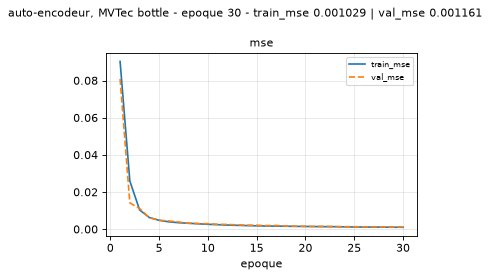

entrainement 56 s | meilleure MSE de validation 0.00113


In [5]:
def flips(x: torch.Tensor) -> torch.Tensor:  # augmentation : retournements aleatoires ; renvoie le lot retourne
    x = x.clone()  # copie : le tenseur d'origine n'est pas modifie
    for dim in (-1, -2):  # -1 = largeur (retournement horizontal), -2 = hauteur (vertical)
        chosen = torch.rand(len(x)) < 0.5  # tirage par image : vrai pour environ la moitie du lot
        x[chosen] = x[chosen].flip(dim)  # retourne les images tirees
    return x  # lot augmente


# entraine un auto-encodeur sur des normales ; renvoie (modele, historique des courbes)
def train_autoencoder(x_tr: torch.Tensor, x_va: torch.Tensor, epochs: int, title: str) -> tuple[ConvAutoencoder, pd.DataFrame]:
    torch.manual_seed(SEED)  # meme graine a chaque appel : poids initiaux reproductibles
    model = ConvAutoencoder(int(x_tr.shape[1]), WIDTHS, LATENT_CHANNELS).to(DEVICE)  # nouvel auto-encodeur, sur GPU ou CPU
    # optimiseur AdamW : corrige les poids a chaque pas d'apres le gradient (direction qui fait baisser l'erreur)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)  # taux / 2 apres 4 epoques sans progres
    generator = torch.Generator().manual_seed(SEED)  # generateur de hasard dedie au melange, graine fixe
    live = viz.LivePlot(metrics=("train_mse", "val_mse"), title=title)  # courbes mises a jour en direct
    best, best_state, bad = float("inf"), None, 0  # meilleure MSE (infinie au depart), poids correspondants, epoques sans progres
    for epoch in range(1, epochs + 1):  # pour chaque epoque
        model.train()  # mode entrainement : BatchNorm suit les statistiques de chaque lot
        order = torch.randperm(len(x_tr), generator=generator)  # ordre melange des images pour cette epoque
        total = 0.0  # somme des pertes de l'epoque
        for i in range(0, len(order), BATCH_SIZE):  # pour chaque lot de BATCH_SIZE images
            xb = flips(x_tr[order[i : i + BATCH_SIZE]]).to(DEVICE)  # lot melange, retourne au hasard, envoye sur GPU ou CPU
            loss = F.mse_loss(model(xb), xb)  # MSE : moyenne des carres des ecarts entre la reconstruction et l'image
            optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent (sinon ils s'additionnent)
            loss.backward()  # retropropagation : calcule le gradient de la perte pour chaque poids
            optimizer.step()  # corrige les poids dans la direction qui fait baisser la perte
            total += loss.item() * len(xb)  # cumule la perte, ponderee par la taille du lot
        model.eval()  # mode evaluation pour mesurer la validation
        with torch.no_grad():  # sans gradient : simple mesure
            val_mse = float(  # MSE moyenne sur les normales de validation
                np.mean(  # moyenne des MSE des paquets
                    # MSE de chaque paquet de 32 images de validation (reconstruction contre image)
                    [F.mse_loss(model(x_va[i : i + 32].to(DEVICE)), x_va[i : i + 32].to(DEVICE)).item() for i in range(0, len(x_va), 32)]
                )
            )
        scheduler.step(val_mse)  # le planning surveille la MSE de validation (baisse le taux si elle stagne)
        live.update(epoch, train_mse=total / len(x_tr), val_mse=val_mse)  # ajoute un point aux courbes
        if val_mse < best:  # si la validation s'ameliore
            best, best_state, bad = val_mse, copy.deepcopy(model.state_dict()), 0  # garde le score et une copie des poids ; compteur a 0
        else:  # sinon (pas de progres)
            bad += 1  # une epoque sans progres de plus
            if bad >= PATIENCE:  # trop d'epoques sans progres
                break  # arret anticipe
    live.close()  # fige les courbes finales
    model.load_state_dict(best_state)  # recharge les poids de la meilleure epoque
    return model.eval(), live.history  # modele en mode evaluation et historique des courbes (tableau pandas)


start = time.time()  # chrono de l'entrainement
autoencoder, history = train_autoencoder(x_train, x_val, EPOCHS, "auto-encodeur, MVTec bottle")  # entraine sur les bouteilles bonnes
train_seconds = time.time() - start  # duree de l'entrainement en secondes
print(f"entrainement {train_seconds:.0f} s | meilleure MSE de validation {history['val_mse'].min():.5f}")  # bilan

## Etape 11 - Evaluer : reconstructions et cartes d'erreur

Ligne du haut : l'image ; au milieu : la reconstruction ; en bas : l'erreur au carre (moyenne
sur les canaux). Sur une normale, l'erreur est faible et diffuse (les bords fins sont flous) ;
sur un defaut, elle devrait se concentrer sur la zone abimee.

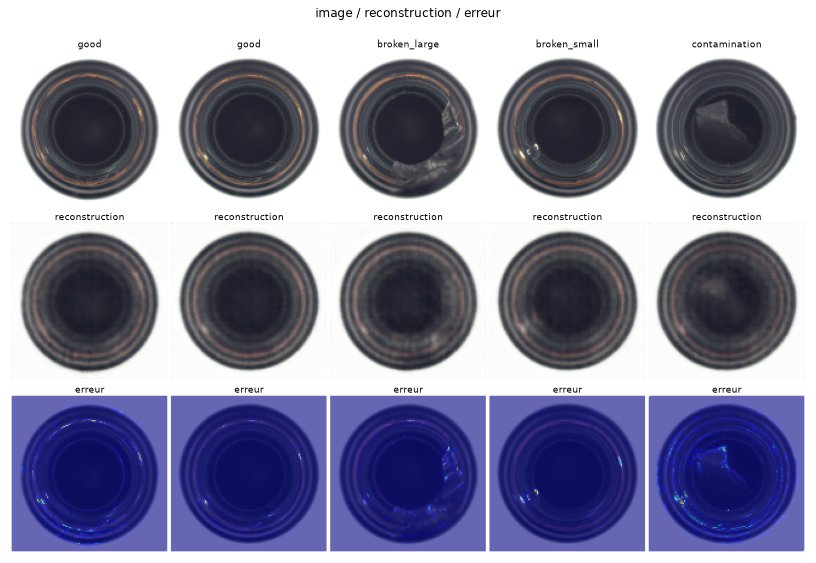

In [6]:
@torch.no_grad()  # pas de calcul de gradient dans cette fonction : plus rapide, moins de memoire
def reconstruct(model: nn.Module, x: torch.Tensor) -> torch.Tensor:  # reconstructions de toutes les images ; renvoie un tenseur
    return torch.cat([model(x[i : i + 32].to(DEVICE)).cpu() for i in range(0, len(x), 32)])  # 32 images a la fois, recollees sur CPU


def as_image(t: torch.Tensor) -> np.ndarray:  # tenseur (C, H, W) dans [0, 1] -> image affichable en 0-255
    array = (t.clamp(0, 1).numpy() * 255).astype(np.uint8)  # borne a [0, 1] puis passe en entiers 0-255
    return array[0] if array.shape[0] == 1 else array.transpose(1, 2, 0)  # gris : (H, W) ; couleur : (H, W, 3)


# 2 images normales + une image par type de defaut
shown = list(frames["test"][test_labels == 0].index[:2]) + list(frames["test"][test_labels == 1].groupby("defect_type").head(1).index)
recon = reconstruct(autoencoder, x_test[shown])  # leurs reconstructions
errors = ((x_test[shown] - recon) ** 2).mean(dim=1)  # erreur au carre par pixel, moyennee sur les canaux : (N, H, W)
viz.grid(  # trois lignes : images, reconstructions, erreurs
    [as_image(x_test[i]) for i in shown]  # ligne 1 : les images
    + [as_image(r) for r in recon]  # ligne 2 : les reconstructions
    + [viz.overlay_heatmap(as_image(x_test[i]), e.numpy(), alpha=0.6) for i, e in zip(shown, errors)],  # ligne 3 : erreur en couleurs
    [frames["test"].loc[i, "defect_type"] for i in shown] + ["reconstruction"] * len(shown) + ["erreur"] * len(shown),  # titres
    ncols=len(shown),  # une colonne par image
    size=2.0,  # largeur de chaque colonne (pouces)
    suptitle="image / reconstruction / erreur",  # titre general
)

## Etape 11 - Evaluer : carte, score, seuil, metriques (le protocole commun)

La carte d'erreur passe par le meme module que toutes les methodes d'anomalie : resize a la
taille de l'image (deja le cas ici), lissage gaussien, score image = maximum. Le seuil est le
quantile 0,99 des scores des normales de validation.

,valeur
auroc_image,0.822
recall,0.556
false_alarm_rate,0.000
f1,0.714
auroc_pixel,0.791


rappel par type : {'broken_large': 0.65, 'broken_small': 0.773, 'contamination': 0.238} | seuil image 0.05693


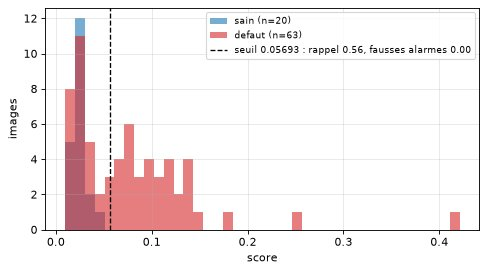

In [7]:
class ReconstructionMap(nn.Module):  # module : image -> carte brute d'erreur de reconstruction
    """Image -> erreur de reconstruction (N, 1, S, S), moyenne sur les canaux."""

    def __init__(self, autoencoder: ConvAutoencoder) -> None:  # garde l'auto-encodeur entraine
        super().__init__()  # initialise la partie nn.Module
        self.autoencoder = autoencoder  # l'auto-encodeur devient un sous-module (exporte avec le reste)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # renvoie la carte d'erreur (N, 1, S, S)
        return ((x - self.autoencoder(x)) ** 2).mean(dim=1, keepdim=True)  # erreur au carre, moyenne des canaux, axe canal garde


def gaussian_kernel(sigma: float) -> torch.Tensor:  # noyau de flou gaussien 2D ; renvoie un tenseur (1, 1, k, k)
    radius = max(1, int(np.ceil(3 * sigma)))  # rayon = 3 sigma (au-dela la gaussienne est quasi nulle), au moins 1
    coords = torch.arange(-radius, radius + 1, dtype=torch.float32)  # positions -rayon ... +rayon
    kernel = torch.exp(-(coords**2) / (2 * sigma**2))  # courbe en cloche (gaussienne) a une dimension
    kernel = kernel / kernel.sum()  # somme ramenee a 1 : le flou ne change pas le niveau moyen
    return torch.outer(kernel, kernel)[None, None]  # produit exterieur -> noyau 2D ; [None, None] ajoute 2 axes (forme d'un filtre)


class MapToScore(nn.Module):  # module : carte brute -> (carte lissee a la taille de l'image, score image)
    def __init__(self, size: int, sigma: float) -> None:  # taille de sortie et force du lissage
        super().__init__()  # initialise la partie nn.Module
        self.size = (size, size)  # taille finale de la carte (hauteur, largeur)
        # noyau range dans le modele (sauve et exporte avec lui) ; sigma = 0 : noyau neutre 1 x 1 (pas de flou)
        self.register_buffer("kernel", gaussian_kernel(sigma) if sigma > 0 else torch.ones(1, 1, 1, 1))

    def forward(self, raw: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (cartes lissees, scores)
        # remet la carte a la taille de l'image (interpolation bilineaire) si elle ne l'est pas deja
        maps = F.interpolate(raw, size=self.size, mode="bilinear", align_corners=False) if raw.shape[-2:] != self.size else raw
        radius = self.kernel.shape[-1] // 2  # rayon du noyau (0 pour le noyau neutre)
        if radius:  # si un lissage est demande
            maps = F.conv2d(F.pad(maps, (radius,) * 4, mode="reflect"), self.kernel)  # bords prolonges en miroir, puis flou (convolution)
        return maps, maps.flatten(1).amax(dim=1)  # carte lissee, et score image = valeur maximale de la carte


class AnomalyModel(nn.Module):  # modele complet image -> (carte, score), meme schema pour toutes les methodes
    def __init__(self, raw_map: nn.Module, to_score: MapToScore) -> None:  # assemble les deux etages
        super().__init__()  # initialise la partie nn.Module
        self.raw_map, self.to_score = raw_map, to_score  # etage 1 : carte brute ; etage 2 : lissage et score

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (carte lissee, score)
        return self.to_score(self.raw_map(x))  # carte brute, puis lissage et score


@torch.no_grad()  # pas de calcul de gradient
def score_images(model: nn.Module, x: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:  # renvoie (scores, cartes) de toutes les images
    model.eval().to(DEVICE)  # mode evaluation, sur GPU ou CPU
    scores, maps = [], []  # resultats paquet par paquet
    for i in range(0, len(x), 16):  # par paquets de 16 images
        m, s = model(x[i : i + 16].to(DEVICE))  # cartes et scores du paquet
        maps.append(m[:, 0].cpu())  # cartes sans l'axe canal, ramenees sur CPU
        scores.append(s.cpu())  # scores ramenes sur CPU
    return torch.cat(scores).numpy(), torch.cat(maps).numpy()  # tout recolle, en tableaux numpy


def anomaly_metrics(scores, maps, masks, labels, threshold, types) -> dict:  # metriques image et pixel ; renvoie un dictionnaire
    decisions = (scores > threshold).astype(int)  # decision par image : 1 = anomalie (score au-dessus du seuil)
    result = {  # metriques par image
        # AUROC : chance qu'un defaut tire au hasard ait un score plus haut qu'une normale (1 = parfait, 0,5 = hasard)
        "auroc_image": float(roc_auc_score(labels, scores)),
        "recall": float(decisions[labels == 1].mean()),  # rappel : part des defauts detectes
        "false_alarm_rate": float(decisions[labels == 0].mean()),  # part des normales signalees a tort
        "f1": float(f1_score(labels, decisions, zero_division=0)),  # F1 : combine precision et rappel (moyenne harmonique)
    }
    if masks.any():  # si des masques de verite existent (au moins un pixel de defaut)
        flat_masks, flat_maps = masks.reshape(-1), maps.reshape(-1)  # tous les pixels mis a plat
        step = max(1, flat_masks.size // 4_000_000)  # pas de sous-echantillonnage : au plus ~4 millions de pixels, pour aller vite
        # AUROC pixel : la carte donne-t-elle des valeurs plus hautes aux pixels de defaut ?
        result["auroc_pixel"] = float(roc_auc_score(flat_masks[::step], flat_maps[::step]))
    # rappel par type de defaut, arrondi a 3 decimales
    result["recall_per_type"] = {t: round(float(decisions[types == t].mean()), 3) for t in sorted(set(types[labels == 1]))}
    return result  # renvoie toutes les metriques


# seuils calibres sur la validation, puis mesure du test ; renvoie (seuils, scores, cartes, metriques)
def evaluate(model: nn.Module, x_va: torch.Tensor, x_te: torch.Tensor, masks: np.ndarray, labels: np.ndarray, types: np.ndarray) -> tuple:
    val_scores, val_maps = score_images(model, x_va)  # scores et cartes des normales de validation
    # seuil image = quantile 0,99 des scores ; seuil pixel = quantile 0,999 des pixels des cartes
    thresholds = {"image": float(np.quantile(val_scores, IMAGE_QUANTILE)), "pixel": float(np.quantile(val_maps, PIXEL_QUANTILE))}
    test_scores, test_maps = score_images(model, x_te)  # scores et cartes du test
    # tout renvoyer, avec les metriques calculees au seuil image
    return thresholds, test_scores, test_maps, anomaly_metrics(test_scores, test_maps, masks, labels, thresholds["image"], types)


model = AnomalyModel(ReconstructionMap(autoencoder), MapToScore(IMAGE_SIZE, SIGMA)).eval()  # modele complet image -> (carte, score)
thresholds, test_scores, test_maps, metrics = evaluate(  # calibre sur la validation, mesure sur le test
    model,  # le modele complet
    x_val,  # normales de validation : servent a fixer les seuils
    x_test,  # images de test : servent a mesurer
    test_masks,  # masques de verite du test (AUROC pixel)
    test_labels,  # verite par image du test (1 = defaut)
    frames["test"]["defect_type"].to_numpy(),  # type de chaque image du test (rappel par type)
)
display(viz.metrics_table({k: v for k, v in metrics.items() if k != "recall_per_type"}))  # tableau des metriques (sans le detail)
print("rappel par type :", metrics["recall_per_type"], "| seuil image", round(thresholds["image"], 5))  # detail par type et seuil
# histogramme des scores (normales / defauts) avec le seuil en trait vertical
viz.score_histogram(test_scores, test_labels.astype(bool), threshold=thresholds["image"], bins=40)

### Les cartes du test

Meme echelle de couleurs pour toutes les images (0 a 2 x seuil pixel) ; contour vert : verite.

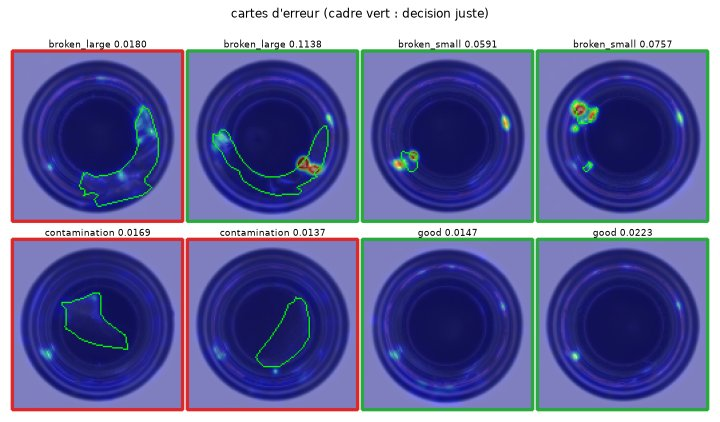

In [8]:
def with_contour(rgb: np.ndarray, mask: np.ndarray) -> np.ndarray:  # dessine en vert le contour du masque de verite sur l'image
    out = np.ascontiguousarray(rgb.copy())  # copie rangee d'un bloc en memoire (exige par les dessins OpenCV)
    # contours exterieurs des zones de defaut, simplifies (seulement les points utiles)
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, (0, 255, 0), 1)  # trace tous les contours (-1) en vert, epaisseur 1 pixel
    return out  # image annotee


# 2 images par type de defaut + 2 normales
chosen = list(frames["test"][test_labels == 1].groupby("defect_type").head(2).index) + list(frames["test"][test_labels == 0].index[:2])
viz.grid(  # grille des cartes du test
    [  # une image par cas choisi
        with_contour(  # contour de la verite dessine par-dessus ...
            # ... la carte d'erreur fondue sur l'image, meme echelle pour toutes (0 a 2 x seuil pixel)
            viz.overlay_heatmap(data["test"][0][i], test_maps[i], alpha=0.5, vmin=0.0, vmax=2 * thresholds["pixel"]),
            test_masks[i],  # le masque de verite dont on trace le contour
        )
        for i in chosen  # pour chaque image choisie
    ],
    [f"{frames['test'].loc[i, 'defect_type']} {test_scores[i]:.4f}" for i in chosen],  # titres : type de defaut et score
    ncols=4,  # 4 images par ligne
    size=2.2,  # largeur de chaque colonne (pouces)
    borders=[bool((test_scores[i] > thresholds["image"]) == test_labels[i]) for i in chosen],  # cadre vert si la decision est juste
    suptitle="cartes d'erreur (cadre vert : decision juste)",  # titre general
)

## Variante (etapes 3 a 11) : pourquoi l'auto-encodeur echoue sur une texture

Le meme fil, refait sur un autre jeu avec les fonctions deja ecrites : cataloguer (3), decouper
(4), lire et pretraiter (5), entrainer (6 a 10), evaluer (11).

Magnetic Tile : des tuiles a la surface texturee et variable (grain, stries, eclairage). Une
texture aleatoire ne se compresse pas dans un goulot : la reconstruction est floue PARTOUT, et
l'erreur est forte sur chaque grain et chaque strie de la texture NORMALE. L'erreur d'un trou ou
d'une fissure se noie dans ce bruit : le score d'une tuile saine ressemble a celui d'une tuile
abimee. Elargir le goulot ne sauve rien : le reseau finit par recopier la texture ET le defaut.
C'est la limite de principe de la reconstruction ; les methodes a caracteristiques
pre-entrainees (PatchCore, notebook 14) comparent des DESCRIPTIONS de zones, pas des pixels, et
tiennent sur les textures
(recette : AUROC image 0,965 pour PatchCore, 0,541 pour l'auto-encodeur).

Le decoupage est celui de la recette `autoencoder_tile` : 20 % des normales en test, 15 % du
reste en validation, tous les defauts en test.

split,test,train,val,All
defect_type,,,,
MT_Blowhole,115,0,0,115
MT_Break,85,0,0,85
MT_Crack,57,0,0,57
MT_Fray,32,0,0,32
MT_Uneven,103,0,0,103
good,191,646,115,952
All,583,646,115,1344


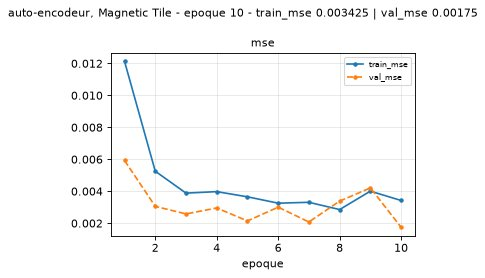

Magnetic Tile (646 normales d'entrainement, 64 s)


,auroc_image,recall,false_alarm_rate,f1,auroc_pixel
bottle (objet),0.822,0.556,0.0,0.714,0.791
magnetic tile (texture),0.547,0.008,0.0,0.015,0.606


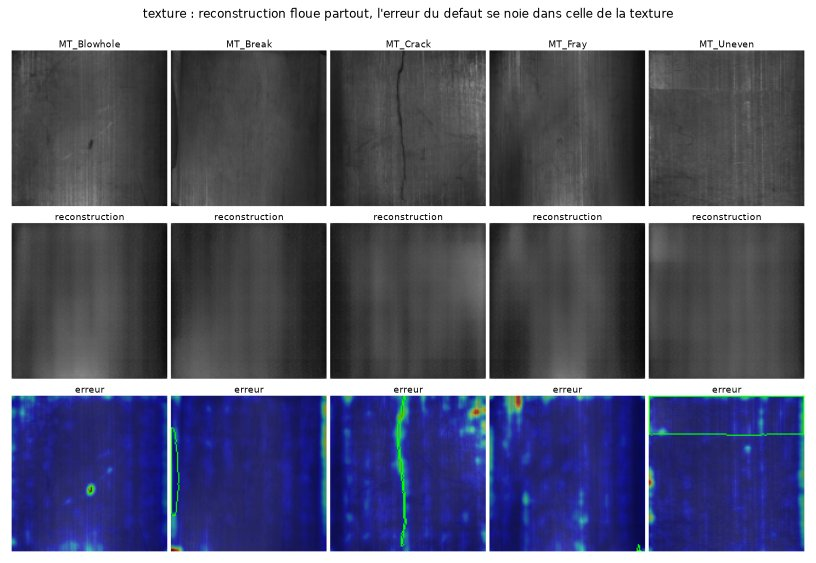

In [9]:
if TEXTURE_DEMO:  # si la demonstration texture est activee
    rows = []  # catalogue des tuiles, une ligne par image
    for p in list_images(TILE_DIR, (".jpg",)):  # pour chaque image .jpg (les .png sont les masques)
        mask = p.parent / f"{p.stem}.png"  # son masque : meme nom, extension .png
        rows.append({"path": str(p), "label": p.relative_to(TILE_DIR).parts[0], "mask_path": str(mask)})  # classe = 1er sous-dossier
    tiles = pd.DataFrame(rows)  # tableau des tuiles
    # type de defaut : "good" pour les tuiles saines (MT_Free), sinon le nom de la classe
    tiles["defect_type"] = np.where(tiles["label"].isin(TILE_NORMAL_LABELS), "good", tiles["label"])
    tiles["label"] = np.where(tiles["label"].isin(TILE_NORMAL_LABELS), "good", "defect")  # etiquette image : good ou defect
    tiles.loc[tiles["label"] == "good", "mask_path"] = ""  # pas de masque pour les tuiles saines
    tile_split = anomaly_split(tiles, VAL_FRACTION, 0.2, SEED)  # 20 % des normales en test, 15 % du reste en validation
    display(pd.crosstab(tile_split["defect_type"], tile_split["split"], margins=True))  # nombre d'images par type et par partie
    # un tableau par partie
    tile_frames = {s: tile_split[tile_split["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
    if TILE_MAX_TRAIN and len(tile_frames["train"]) > TILE_MAX_TRAIN:  # si une limite est fixee et depassee
        # tirage au hasard (graine fixe) d'un sous-ensemble des normales d'entrainement
        tile_frames["train"] = tile_frames["train"].sample(n=TILE_MAX_TRAIN, random_state=SEED).reset_index(drop=True)
    tile_data = {s: load_subset(tile_frames[s], "gray", IMAGE_SIZE) for s in tile_frames}  # images grises et masques de chaque partie
    t_train, t_val, t_test = (to_tensor(tile_data[s][0]) for s in ("train", "val", "test"))  # images en tenseurs (N, 1, H, W)
    t_labels = (tile_frames["test"]["label"] == "defect").to_numpy().astype(int)  # verite par image du test : 1 = defaut
    start = time.time()  # chrono
    tile_ae, _ = train_autoencoder(t_train, t_val, TILE_EPOCHS, "auto-encodeur, Magnetic Tile")  # meme auto-encodeur, sur les tuiles saines
    tile_model = AnomalyModel(ReconstructionMap(tile_ae), MapToScore(IMAGE_SIZE, SIGMA)).eval()  # modele complet image -> (carte, score)
    tile_thr, tile_scores, tile_maps, tile_metrics = evaluate(  # seuils sur la validation, metriques du test
        tile_model,  # le modele complet des tuiles
        t_val,  # tuiles saines de validation : fixent les seuils
        t_test,  # tuiles de test
        tile_data["test"][1],  # masques de verite du test
        t_labels,  # verite par image du test
        tile_frames["test"]["defect_type"].to_numpy(),  # type de chaque tuile du test
    )
    print(f"Magnetic Tile ({len(t_train)} normales d'entrainement, {time.time() - start:.0f} s)")  # taille et duree
    display(  # affiche ...
        viz.metrics_table(  # ... un tableau comparatif objet / texture
            {  # une ligne par jeu de donnees
                "bottle (objet)": {k: v for k, v in metrics.items() if k != "recall_per_type"},  # bouteilles (sans le detail par type)
                "magnetic tile (texture)": {k: v for k, v in tile_metrics.items() if k != "recall_per_type"},  # tuiles, idem
            }
        )
    )
    picks = list(tile_frames["test"][t_labels == 1].groupby("defect_type").head(1).index)  # une tuile par type de defaut
    t_recon = reconstruct(tile_ae, t_test[picks])  # leurs reconstructions
    viz.grid(  # images / reconstructions / erreurs
        [as_image(t_test[i]) for i in picks]  # ligne 1 : les tuiles
        + [as_image(r) for r in t_recon]  # ligne 2 : les reconstructions (floues partout)
        # ligne 3 : la carte d'erreur sur la tuile, avec le contour vert de la verite
        + [with_contour(viz.overlay_heatmap(tile_data["test"][0][i], tile_maps[i], alpha=0.5), tile_data["test"][1][i]) for i in picks],
        [tile_frames["test"].loc[i, "defect_type"] for i in picks] + ["reconstruction"] * len(picks) + ["erreur"] * len(picks),  # titres
        ncols=len(picks),  # une colonne par tuile
        size=2.0,  # largeur de chaque colonne (pouces)
        suptitle="texture : reconstruction floue partout, l'erreur du defaut se noie dans celle de la texture",  # titre general
    )

## Etape 12 - Sauvegarder et exporter : MVTec bottle, image [0, 1] -> (carte, score)

Le module complet (auto-encodeur + erreur + lissage + score) est exporte ; le seuil va dans la
carte du modele. Verification sur un lot de 3 (export avec un lot de 2).

In [10]:
model = model.eval().cpu()  # mode evaluation et retour sur CPU pour l'export
onnx_path = OUT / "model.onnx"  # fichier ONNX : le modele dans un format lisible sans PyTorch (production)
with warnings.catch_warnings():  # dans ce bloc, les avertissements sont geres a part ...
    warnings.simplefilter("ignore")  # ... et masques (l'export en produit beaucoup)
    torch.onnx.export(  # fait passer un exemple dans le modele, enregistre les operations et les ecrit au format ONNX
        model,  # modele complet : auto-encodeur + erreur + lissage + score
        (x_val[:2],),  # exemple d'entree : un lot de 2 images de validation
        str(onnx_path),  # chemin du fichier a ecrire
        input_names=["input"],  # nom de l'entree dans le graphe ONNX
        output_names=["anomaly_map", "score"],  # noms des deux sorties
        dynamic_axes={"input": {0: "batch"}, "anomaly_map": {0: "batch"}, "score": {0: "batch"}},  # taille du lot (axe 0) libre partout
        opset_version=18,  # version du jeu d'operations ONNX
        dynamo=False,  # exporteur classique (par tracage), stable pour ce modele
    )
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le fichier ONNX dans onnxruntime (CPU)
with torch.no_grad():  # sans gradient : simple prediction
    expected = [t.numpy() for t in model(x_val[:3])]  # reponses PyTorch (carte, score) sur un lot de 3 (taille differente de l'export)
got = session.run(None, {"input": x_val[:3].numpy()})  # reponses d'onnxruntime sur les memes images
report = {}  # ecart maximal pour chaque sortie
for name, t, o in zip(("anomaly_map", "score"), expected, got):  # pour chaque sortie : nom, reponse PyTorch, reponse ONNX
    diff, scale = float(np.abs(t - o).max()), float(np.abs(t).max())  # plus grand ecart, et ordre de grandeur des valeurs
    report[name] = diff  # note l'ecart
    assert diff <= 1e-4 + 1e-3 * scale, f"{name} : ecart ONNX / PyTorch {diff:.2e}"  # doivent concorder (tolerance relative), sinon arret


def latency_ms(fn, runs: int = 20) -> float:  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels de chauffe non chronometres ...
        fn()  # ... (le premier appel est toujours plus lent : allocations, caches)
    start = time.perf_counter()  # chrono precis
    for _ in range(runs):  # `runs` appels chronometres
        fn()  # un appel du modele
    return round(1000 * (time.perf_counter() - start) / runs, 2)  # duree moyenne en ms, arrondie a 2 decimales


one = x_val[:1]  # une seule image (lot de 1) : la latence vue par la production
with torch.no_grad():  # sans gradient
    latency = {  # latence des deux moteurs
        "torch_cpu_ms": latency_ms(lambda: model(one)),  # PyTorch sur CPU (lambda : petite fonction sans nom)
        "onnxruntime_cpu_ms": latency_ms(lambda: session.run(None, {"input": one.numpy()})),  # onnxruntime sur CPU
    }
print(f"ONNX verifie {report} | latence {latency}")  # ecarts par sortie et latences

channels = int(x_train.shape[1])  # nombre de canaux des images (3 en couleur)
card = {  # carte du modele : tout ce que la production doit savoir pour l'utiliser
    "task": "anomaly",  # type de tache : detection d'anomalies
    "model_name": "autoencoder",  # nom du modele
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),  # date et heure de creation (UTC)
    "framework": {"torch": torch.__version__, "onnxruntime": ort.__version__},  # versions des bibliotheques
    "input": {  # description de l'entree attendue
        "name": "input",  # nom de l'entree dans le graphe ONNX
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": IMAGE_SIZE,  # hauteur en pixels
        "width": IMAGE_SIZE,  # largeur en pixels
        "channels": channels,  # nombre de canaux
        "color": "RGB" if channels == 3 else "GRAY",  # couleur ou gris
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle [0, 1] a faire avant l'envoi
        "mean": [],  # vide : pas de normalisation a faire
        "std": [],  # vide aussi
        "resize": "stretch",  # redimensionnement en etirant (proportions non conservees)
        "letterbox_pad_value": None,  # pas de letterbox (bandes ajoutees pour garder les proportions)
        "dynamic_batch": True,  # taille de lot libre
        "read_color": COLOR,  # mode de lecture de l'image
    },
    "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # pretraitement : resize, interpolation automatique
    "outputs": [  # description des deux sorties
        {  # sortie 1 : la carte
            "name": "anomaly_map",  # son nom
            "shape": ["batch", 1, IMAGE_SIZE, IMAGE_SIZE],  # sa forme : lot, 1 canal, hauteur, largeur
            "description": "carte d'anomalie lissee (plus haut = plus anormal)",  # ce qu'elle contient
        },
        {"name": "score", "shape": ["batch"], "description": "score image ; anomalie si score > thresholds.image"},  # sortie 2 : le score
    ],
    "class_names": [],  # pas de classes : seulement normal ou anomalie
    "thresholds": thresholds,  # seuils image et pixel calibres sur la validation
    # regle de decision et origine du seuil
    "postprocess": {"decision": "score > thresholds.image", "calibration": f"quantile {IMAGE_QUANTILE} des normales de validation"},
    # metriques principales du test, arrondies a 4 decimales
    "metrics": {k: round(v, 4) for k, v in metrics.items() if k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "f1")},
    "latency_ms": latency,  # latences mesurees
    "files": {"onnx": "model.onnx"},  # fichier du modele, a cote de la carte
    "notes": f"auto-encodeur ecrit dans le notebook 13 ; ecarts ONNX / PyTorch {report}",  # note libre
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible
print("ecrit :", sorted(p.name for p in OUT.iterdir()))  # liste les fichiers du dossier de sortie

ONNX verifie {'anomaly_map': 1.1175870895385742e-08, 'score': 7.450580596923828e-09} | latence {'torch_cpu_ms': 6.61, 'onnxruntime_cpu_ms': 3.78}
ecrit : ['model.onnx', 'model_card.json', 'split.csv']


## Resultats

References de la recette (256 px, 30 epoques sur bottle ; 20 epoques sur Magnetic Tile) :
`autoencoder_bottle` AUROC image 0,788 / pixel 0,720 ; `autoencoder_tile` 0,541 / 0,595.
PatchCore (notebook 14) : 1,000 / 0,982 sur bottle sans entrainement.

In [11]:
rows = [  # tableau de comparaison, une ligne par resultat
    {  # ligne : ce notebook sur bottle
        "source": f"notebook 13 bottle ({IMAGE_SIZE} px)",  # description
        **{k: round(metrics[k], 3) for k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate")},  # ** recopie 4 metriques
        "entrainement_s": round(train_seconds),  # duree d'entrainement en secondes
    }
]
if TEXTURE_DEMO:  # si la demonstration texture a tourne
    rows.append(  # ajoute sa ligne
        {  # ligne : ce notebook sur magnetic tile
            "source": f"notebook 13 magnetic tile ({len(t_train)} normales)",  # description
            **{k: round(tile_metrics[k], 3) for k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate")},  # ses 4 metriques
        }
    )
rows += [  # lignes de reference de la recette
    # recette sur les bouteilles (256 px)
    {"source": "recette autoencoder_bottle (256 px)", "auroc_image": 0.788, "auroc_pixel": 0.720, "recall": 0.460, "false_alarm_rate": 0.0},
    # recette sur les tuiles (256 px) : proche du hasard
    {"source": "recette autoencoder_tile (256 px)", "auroc_image": 0.541, "auroc_pixel": 0.595, "recall": 0.028, "false_alarm_rate": 0.005},
]
display(pd.DataFrame(rows))  # affiche le tableau

,source,auroc_image,auroc_pixel,recall,false_alarm_rate,entrainement_s
0,notebook 13 bottle (128 px),0.822,0.791,0.556,0.000,56.0
1,notebook 13 magnetic tile (646 normales),0.547,0.606,0.008,0.000,NaN
2,recette autoencoder_bottle (256 px),0.788,0.720,0.460,0.000,NaN
3,recette autoencoder_tile (256 px),0.541,0.595,0.028,0.005,NaN


## Adapter a tes donnees

- Rangement MVTec : changer `DATA_DIR`. Autre rangement : un catalogue path / label (good,
  defect) / defect_type / mask_path, comme dans la variante sur une texture, puis `anomaly_split`.
- Quand choisir l'auto-encodeur : images loin d'ImageNet (radiographie, thermique, spectres),
  modele minuscule exige, ou pieces tres regulieres. Sinon, commencer par PatchCore (notebook 14).
- Le goulot : essayer `LATENT_CHANNELS` 8, 16, 32, 64 et comparer l'AUROC sur une validation
  qui contient quelques defauts (jamais sur le test).
- `IMAGE_SIZE` doit etre un multiple de 16 (4 etages de pas 2).

## Passer en production

```yaml
# recipes/anomaly/configs/autoencoder_bottle.yaml
data: {root: data/raw/mvtec_bottle, layout: mvtec}
normal_labels: [good]
split: {file: outputs/anomaly/bottle_split.csv, val_fraction: 0.15}
preprocess: [{name: resize, size: 256}]
scoring: {gaussian_sigma: 4.0, image_score: max, image_quantile: 0.99}
method: autoencoder
autoencoder: {latent_channels: 32, widths: [32, 64, 128, 256], epochs: 30, batch_size: 16, lr: 0.001, patience: 8}
augment: [{name: hflip}, {name: vflip}]
```

```
python recipes/anomaly/scripts/run.py --config recipes/anomaly/configs/autoencoder_bottle.yaml
python -m vtb.serve --model outputs/notebooks/13_anomalies_autoencodeur
```

Controle : le predicteur de production relit le dossier exporte par ce notebook et doit rendre
les memes scores ; les decoupages doivent etre ceux de la recette.

In [12]:
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - production seulement dans cette section (predicteur sans PyTorch)

predictor = OnnxPredictor(OUT)  # charge le modele ONNX et sa carte depuis le dossier exporte
picked = list(range(0, len(frames["test"]), max(1, len(frames["test"]) // 8)))[:8]  # 8 images du test reparties regulierement
# ecart de score entre le predicteur de production (depuis le fichier image brut) et le notebook, image par image
gaps = [abs(predictor(read_image(frames["test"].loc[i, "path"], predictor.color))["score"] - float(test_scores[i])) for i in picked]
# plus grand ecart, compare a l'ordre de grandeur des scores (mediane)
print(f"predicteur de production : ecart max des scores {max(gaps):.2e} (scores de l'ordre de {np.median(test_scores):.4f})")
assert max(gaps) <= 1e-3 * float(np.abs(test_scores).max())  # tolerance : 0,1 % du plus grand score, sinon arret

checks = [("bottle", split, Path("outputs/anomaly/bottle_split.csv"))]  # decoupages a comparer a ceux de la recette
if TEXTURE_DEMO:  # si la demonstration texture a tourne
    checks.append(("magnetic tile", tile_split, Path("outputs/anomaly/tile_split.csv")))  # ajoute son decoupage
for name, ours_split, recipe_path in checks:  # pour chaque decoupage : nom, le notre, fichier de la recette
    if recipe_path.exists():  # si la recette a deja ete lancee
        theirs = pd.read_csv(recipe_path, keep_default_na=False).set_index("path")["split"]  # partie de chaque image selon la recette
        ours = ours_split.set_index("path")["split"]  # partie de chaque image selon ce notebook
        # identique si chaque image est dans la meme partie (reindex aligne les deux tableaux par chemin)
        print(f"decoupage {name} identique a la recette : {bool((theirs.reindex(ours.index) == ours).all())}")
    else:  # sinon (recette pas encore lancee)
        print(f"decoupage {name} : recette non lancee ({recipe_path})")  # signale le fichier manquant

predicteur de production : ecart max des scores 2.98e-08 (scores de l'ordre de 0.0337)
decoupage bottle identique a la recette : True
decoupage magnetic tile identique a la recette : True


## Pour aller plus loin

- `14_anomalies_patchcore` : la reference, sans entrainement.
- `15_anomalies_anomalib` : STFPM, FastFlow, Reverse Distillation (des reseaux entraines eux
  aussi, mais qui comparent des caracteristiques, pas des pixels).
- Perte SSIM au lieu de MSE : plus sensible a la structure qu'a l'intensite (un classique pour
  les auto-encodeurs d'inspection).